# Self-supervised learning: no labels

<p class="nb-download">Run it yourself: <a href="_static/notebooks/self_supervised.ipynb" download>this notebook</a> · <a href="_static/geoai_hexagons.zip" download>all notebooks, the helpers and the data (zip)</a></p>

```{admonition} Question
:class: tip
Can a model describe places without any label?
```

**In this notebook:** 1 · a pretext task  2 · the embedding  3 · places like Otaniemi  4 · two checks  5 · 30 labels

## 1 · A pretext task

A **pretext task** is a task whose answers are already in the data. Ours: from the counts of a hexagon, predict the counts around it, `W @ X` (the spatial lag of week 3).

In [1]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

import helpers as h

hexes, X, y, W = h.load()        # the table, the features, the labels, the neighbours
SEED = 0

The model is a small neural network with a narrow layer of 8 units in the middle. Whatever it learns about a hexagon has to pass through those 8 numbers.

In [2]:
own = StandardScaler().fit_transform(X)              # input: the counts of the hexagon itself
around = StandardScaler().fit_transform(W @ X)       # target: the counts around it (no land-use label anywhere)

net = MLPRegressor(hidden_layer_sizes=(32, 8, 32), alpha=1e-3, max_iter=3000, random_state=SEED)
net.fit(own, around)
print(f"pretext task, on the hexagons the network was trained on: R² = {net.score(own, around):.2f}")

pretext task, on the hexagons the network was trained on: R² = 0.77


## 2 · The embedding

The first half of the network is the **encoder**. Its output, 8 numbers per hexagon, is the **embedding**.

In [3]:
def encode(net, inputs, layers=2):
    """Run the inputs through the first layers of the network and stop at the narrow 8-number layer."""
    a = inputs
    for weights, bias in list(zip(net.coefs_, net.intercepts_))[:layers]:
        a = np.maximum(a @ weights + bias, 0)        # ReLU
    return a


E = StandardScaler().fit_transform(encode(net, own))    # the embedding: 8 numbers per hexagon
QUERY = h.five(hexes)["Otaniemi"]                       # or: h.hexagon_at(hexes, lon, lat)
print("embedding of the Otaniemi hexagon:", np.round(E[QUERY], 2))

embedding of the Otaniemi hexagon: [ 1.28 -0.58 -0.94  0.9  -0.28  2.94  1.29  2.23]


A single number of the embedding has no meaning to us. What matters is distance: hexagons that are alike should lie close together.

## 3 · Places like Otaniemi

A similarity search: the 12 hexagons nearest to Otaniemi in the embedding.

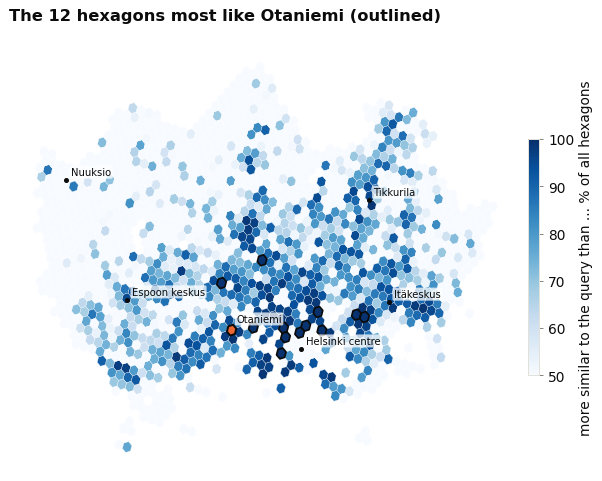

In [4]:
def most_similar(M, query, k=12):
    """The k rows of M nearest to the row `query`, and the distance of every row to it."""
    distance = np.linalg.norm(M - M[query], axis=1)
    order = np.argsort(distance)
    return order[order != query][:k], distance


top, distance = most_similar(E, QUERY)
h.map_similar(hexes, distance, top, QUERY);

The table lists the 12. The column `landmarks` names a university or a shopping centre first wherever a hexagon has one, so read it with care.

In [5]:
def stands_out(i, k=4):
    """The k kinds of POI of which hexagon i has unusually many, compared with all hexagons."""
    return ", ".join(np.array(h.FEATURES)[np.argsort(-own[i])[:k]])


xy = hexes[["x", "y"]].to_numpy()                    # the centre of every hexagon, in metres
table = hexes.iloc[top][["landmarks", "poi_total", "landuse"]].copy()
table.insert(0, "km from query", np.round(np.linalg.norm(xy[top] - xy[QUERY], axis=1) / 1000, 1))
table["stands out for"] = [stands_out(i) for i in top]
print("Otaniemi stands out for:", stands_out(QUERY))
print("hexagons of the list that touch Otaniemi:", len(set(top) & set(W[QUERY].indices)))
table.reset_index(drop=True)

Otaniemi stands out for: culture, office, food, bike
hexagons of the list that touch Otaniemi: 0


,km from query,landmarks,poi_total,landuse,stands out for
0,6.2,Helsingin kaupunginteatteri; Eläintarhanlahden...,205,green,"culture, health, education, food"
1,8.0,Diakonia-ammattikorkeakoulu; Yrkeshögskolan Ar...,343,residential,"craft_industry, shop_daily, culture, office"
2,4.9,Kivelän sairaala; Töölön kirjasto,206,green,"lodging, culture, bike, shop_daily"
3,5.0,Kauppakeskus Ruoholahti; Biitsi Salmisaari,186,work,"finance, culture, shop_daily, craft_industry"
4,8.2,Redi; BioRex Redi,450,work,"culture, shop_daily, food, shop_other"
5,4.7,Meilahden sairaala-alue; Töölön uimahalli,317,residential,"culture, craft_industry, bike, office"
6,11.4,Noli Herttoniemi; Herttoniemen Montessori-leik...,123,residential,"lodging, culture, street_furniture, bike"
7,4.3,Laurea-ammattikorkeakoulu Leppävaaran kampus; ...,461,residential,"finance, shop_daily, food, shop_other"
8,12.1,"Careeria; Stadin Ammattiopisto, Abraham Wetter...",117,work,"culture, food, shop_other, civic"
9,6.9,Kannelmäen kirjasto; Kannelmäen liikuntapuisto,257,residential,"culture, health, shop_other, shop_daily"


In [6]:
assert len(top) == 12 and not set(top) & set(W[QUERY].indices)

**Result.** The 12 hexagons lie 2 to 12 km from Otaniemi and none touches it. Eleven stand out for `culture`, as Otaniemi does. Their labels differ: similar surroundings are not the same land use.

## 4 · Embedding or raw counts?

Two checks: the same search in the raw counts, and how often the six most similar hexagons of a hexagon carry its label. For comparison, 8 principal components (PCA), a plain summary of the same size.

In [7]:
top_raw, _ = most_similar(own, QUERY)
print(f"the search in the raw counts shares {len(set(top) & set(top_raw))} of {len(top)} hexagons with the search in the embedding")


def like_with_like(M, k=6):
    """Share of the k most similar hexagons (in the space M) that carry the same land-use label."""
    idx = NearestNeighbors(n_neighbors=k + 1).fit(M).kneighbors(M)[1][:, 1:]
    return (y[idx] == y[:, None]).mean()


pca8 = StandardScaler().fit_transform(PCA(n_components=8, random_state=SEED).fit_transform(own))
options = {"raw POI profile (16 numbers)": own, "PCA of the profile (8 numbers)": pca8, "our embedding (8 numbers)": E}
for name, M in options.items():
    print(f"{name:32s} {like_with_like(M):.0%}")
same_as_neighbours = np.mean([np.mean(y[W[i].indices] == y[i]) for i in range(len(y)) if W[i].nnz])
print(f"{'the hexagons that touch it':32s} {same_as_neighbours:.0%}")

the search in the raw counts shares 1 of 12 hexagons with the search in the embedding


raw POI profile (16 numbers)     72%
PCA of the profile (8 numbers)   71%
our embedding (8 numbers)        68%


the hexagons that touch it       69%


**Result.** The two searches share 1 of 12 hexagons: the network changed the answer. By this measure it did not improve it: 68% in the embedding, 72% in the raw counts.

## 5 · 30 labels

The **downstream task** is the reason to learn an embedding first: a few labels should then go further. The classifier of the page before, fitted on 30 hexagons drawn at random and tested on the other 1,429, in twelve draws.

raw POI profile (16 numbers)     73.4%  (± 2.2% between draws)
PCA of the profile (8 numbers)   73.2%  (± 1.9% between draws)
our embedding (8 numbers)        71.7%  (± 2.9% between draws)


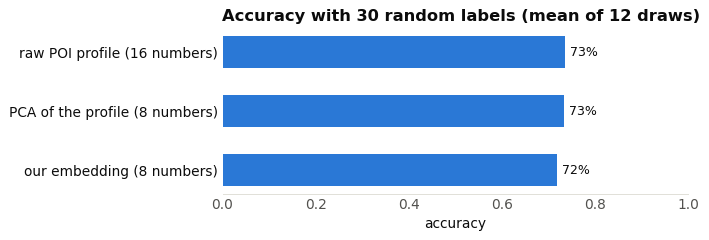

In [8]:
def few_label_accuracy(M, seeds=range(12)):
    scores = []
    for seed in seeds:
        lab = h.draw_labelled(y, 30, seed)                   # 30 hexagons at random
        rest = np.setdiff1d(np.arange(len(y)), lab)
        scores.append((h.new_model().fit(M[lab], y[lab]).predict(M[rest]) == y[rest]).mean())
    return np.mean(scores), np.std(scores)


results = {name: few_label_accuracy(M) for name, M in options.items()}
for name, (m, s) in results.items():
    print(f"{name:32s} {m:.1%}  (± {s:.1%} between draws)")
h.plot_few_labels(results);

In [9]:
assert [f"{results[k][0]:.0%}" for k in ("our embedding (8 numbers)", "raw POI profile (16 numbers)")] == ["72%", "73%"]

**Result.** 72% with the embedding against 73% with the raw counts, a difference smaller than the spread between draws. On a table this small the embedding supports search and does not improve prediction. Embeddings pay off where the input is large and unstructured, such as satellite images, and labels are rare. AlphaEarth Foundations works in that setting: 64 numbers for every 10 m pixel.

**Next:** [reinforcement learning](reinforcement)